# IMPORT LIBRARY YANG DI BUTUHKAN

In [194]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score, classification_report
from sklearn.tree import DecisionTreeClassifier
import joblib


## 1. DATA LOADING

### 1.1. Memeriksa Jumlah Data dan Kolom
Dataset memiliki **374.917 baris** dan **17 kolom**.
### 1.2. Melihat 5 Baris Pertama
Menampilkan lima baris pertama untuk memahami struktur dan isi dataset.
### 1.3. Memeriksa Tipe Data
Memeriksa tipe data setiap kolom untuk mengetahui apakah data bertipe numerik, kategorikal, atau tanggal.
### 1.4. Memeriksa Deskripsi Dataset
Melihat ringkasan statistik deskriptif dari dataset.
### 1.5. Memeriksa Missing Values
Memeriksa jumlah nilai yang hilang pada setiap kolom. Memeriksa di tahun berapa nilai yang hiang tersebut berada dan apakah semua kolomnya berada di baris yang sama.
### 1.6. Memeriksa Data Duplikat
Memeriksa apakah terdapat baris data yang duplikat.
### 1.7. Memeriksa Distribusi `base_severity` (Kandidat Target)
Distribusi kelas menunjukkan ketidakseimbangan data.
Kelas **MEDIUM** dan **HIGH** memiliki jumlah sampel lebih banyak dibandingkan kelas lainnya.
### 1.8. Memeriksa Distribusi `cisa_kev` (Kandidat Target)
Seluruh baris pada kolom `cisa_kev` memiliki nilai **`False`**.
Kolom ini tidak memiliki variasi nilai sehingga tidak dapat digunakan sebagai target klasifikasi yang bermakna pada dataset ini.

In [195]:
train = pd.read_csv("cve_cisa_epss_enriched_dataset.csv")
print("Ukuran Dataset: ", train.shape)

Ukuran Dataset:  (374917, 17)


In [196]:
# Memeriksa 5 baris pertama
train.head()

,cve_id,base_severity,base_score,exploitability_score,impact_score,epss_score,epss_perc,cisa_kev,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality_impact,integrity_impact,availability_impact,published_date
0,CVE-1999-0095,HIGH,10.0,10.0,10.0,0.16317,0.96889,False,NETWORK,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1988-10-01 04:00:00
1,CVE-1999-0082,HIGH,10.0,10.0,10.0,0.08281,0.94791,False,NETWORK,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1988-11-11 05:00:00
2,CVE-1999-1471,HIGH,7.2,3.9,10.0,0.00503,0.41171,False,LOCAL,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1989-01-01 05:00:00
3,CVE-1999-1122,MEDIUM,4.6,3.9,6.4,0.00383,0.30219,False,LOCAL,LOW,NaN,NaN,NaN,PARTIAL,PARTIAL,PARTIAL,1989-07-26 04:00:00
4,CVE-1999-1467,HIGH,10.0,10.0,10.0,0.10249,0.95581,False,NETWORK,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1989-10-26 04:00:00


In [197]:
# Memeriksa tipe data
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 374917 entries, 0 to 374916
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   cve_id                  374917 non-null  str    
 1   base_severity           374917 non-null  str    
 2   base_score              374917 non-null  float64
 3   exploitability_score    374917 non-null  float64
 4   impact_score            374917 non-null  float64
 5   epss_score              374646 non-null  float64
 6   epss_perc               374646 non-null  float64
 7   cisa_kev                374917 non-null  bool   
 8   attack_vector           374917 non-null  str    
 9   attack_complexity       374917 non-null  str    
 10  privileges_required     302512 non-null  str    
 11  user_interaction        302512 non-null  str    
 12  scope                   302512 non-null  str    
 13  confidentiality_impact  374917 non-null  str    
 14  integrity_impact        374917 

In [198]:
train.describe(include="all")

,cve_id,base_severity,base_score,exploitability_score,impact_score,epss_score,epss_perc,cisa_kev,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality_impact,integrity_impact,availability_impact,published_date
count,374917,374917,374917.000000,374917.000000,374917.000000,374646.000000,374646.000000,374917,374917,374917,302512,302512,302512,374917,374917,374917,374917
unique,374917,5,NaN,NaN,NaN,NaN,NaN,1,4,3,3,2,2,5,5,5,346510
top,CVE-1999-0095,MEDIUM,NaN,NaN,NaN,NaN,NaN,False,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH,2004-12-31 05:00:00.000
freq,1,170990,NaN,NaN,NaN,NaN,NaN,374917,283041,315686,168647,208089,240979,153489,129956,149772,1098
mean,NaN,NaN,6.804152,3.728966,4.464240,0.027521,0.507326,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,1.798358,2.587553,1.926676,0.090306,0.287467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,0.000000,0.100000,0.000000,0.000490,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,5.400000,1.800000,2.900000,0.003450,0.259410,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,7.000000,2.800000,3.700000,0.006840,0.511440,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,7.800000,3.900000,5.900000,0.016350,0.756130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [199]:
# Memeriksa missing values
train.isnull().sum()

cve_id                        0
base_severity                 0
base_score                    0
exploitability_score          0
impact_score                  0
epss_score                  271
epss_perc                   271
cisa_kev                      0
attack_vector                 0
attack_complexity             0
privileges_required       72405
user_interaction          72405
scope                     72405
confidentiality_impact        0
integrity_impact              0
availability_impact           0
published_date                0
dtype: int64

In [200]:
# Memeriksa duplikat
train.duplicated().sum()

np.int64(0)

In [201]:
# Distribusi tingkat keparahan
train["base_severity"].value_counts(dropna=False)


base_severity
MEDIUM      170990
HIGH        150664
CRITICAL     36970
LOW          16246
NONE            47
Name: count, dtype: int64

In [202]:
train["cisa_kev"].value_counts(dropna=False)

cisa_kev
False    374917
Name: count, dtype: int64

In [203]:
# Menghitung presentase nilai kosong dalam kolom
missing_percent = (train.isnull().sum() / len(train)) * 100
missing_percent[missing_percent > 0].sort_values(ascending=False)

privileges_required    19.312274
scope                  19.312274
user_interaction       19.312274
epss_score              0.072283
epss_perc               0.072283
dtype: float64

In [204]:
colms = ["user_interaction", "privileges_required", "scope"]

# HItung berapa baris yang kosong pada ketiga kolom
all_missing = train[colms].isnull().all(axis=1).sum()
# Hitng baris kosong pada setidaknya 1 kolom
any_missing = train[colms].isnull().any(axis=1).sum()

print("Kosong pada ke-3 kolom: ", all_missing)
print("Kosong pada minmal satu kolom: ", any_missing)

Kosong pada ke-3 kolom:  72405
Kosong pada minmal satu kolom:  72405


In [205]:
year = pd.to_datetime(train["published_date"], errors="coerce").dt.year
missing_by_year = train.groupby(year).agg(
    jumlah_baris = ("cve_id", "size"),
    jumlah_missing = ("user_interaction", lambda s: s.isnull().sum())
)

missing_by_year["persen_missing"] = (
    missing_by_year["jumlah_missing"] / missing_by_year["jumlah_baris"] * 100
)

print(missing_by_year)
# Memeriksa apakah ada missing value yang lebih dari tahun 2002
missing_by_year[missing_by_year.index > 2002]

                jumlah_baris  jumlah_missing  persen_missing
published_date                                              
1988.0                     2               2      100.000000
1989.0                     3               3      100.000000
1990.0                    11              10       90.909091
1991.0                    15              15      100.000000
1992.0                    13              13      100.000000
1993.0                    13              13      100.000000
1994.0                    25              25      100.000000
1995.0                    25              24       96.000000
1996.0                    74              72       97.297297
1997.0                   252             242       96.031746
1998.0                   246             236       95.934959
1999.0                   894             885       98.993289
2000.0                  1019            1009       99.018646
2001.0                  1675            1637       97.731343
2002.0                  

,jumlah_baris,jumlah_missing,persen_missing
published_date,,,


In [206]:
colms = ["epss_perc", "epss_score"]

# HItung berapa baris yang kosong pada kedua kolom
all_missing = train[colms].isnull().all(axis=1).sum()
# Hitng baris kosong pada setidaknya 1 kolom
any_missing = train[colms].isnull().any(axis=1).sum()

print("Kosong pada ke-2 kolom: ", all_missing)
print("Kosong pada minmal satu kolom: ", any_missing)

Kosong pada ke-2 kolom:  271
Kosong pada minmal satu kolom:  271


## 2. Data Cleaning
### 2.1 Mengapus Missing Values
baris yang nilainya hilang dihapus karena baris tersebut berada di tahun yang lampau tepatnya 1988-2002 yang di mana CVSS 3 belum digunakan.
### 2.2 Menghapus kolom yang tidak digunakan.


In [207]:
colms = ["user_interaction", "privileges_required", "scope"]
print("Jumlah data sebelum di bersihkan: ", len(train))
train_clean = train.dropna(subset=colms).copy()
print("Jumlah data sesudah di bersihkan: ", len(train_clean))
train_clean.isnull().sum()

Jumlah data sebelum di bersihkan:  374917
Jumlah data sesudah di bersihkan:  302512


cve_id                      0
base_severity               0
base_score                  0
exploitability_score        0
impact_score                0
epss_score                271
epss_perc                 271
cisa_kev                    0
attack_vector               0
attack_complexity           0
privileges_required         0
user_interaction            0
scope                       0
confidentiality_impact      0
integrity_impact            0
availability_impact         0
published_date              0
dtype: int64

In [208]:
kolom = ["cve_id",
        "base_score",
        "exploitability_score",
        "impact_score",
        "epss_score",
        "epss_perc",
        "cisa_kev",
        "published_date"
        ]
df = train_clean.drop(columns=kolom)
df.info()
df.head()


<class 'pandas.DataFrame'>
Index: 302512 entries, 6 to 374916
Data columns (total 9 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   base_severity           302512 non-null  str  
 1   attack_vector           302512 non-null  str  
 2   attack_complexity       302512 non-null  str  
 3   privileges_required     302512 non-null  str  
 4   user_interaction        302512 non-null  str  
 5   scope                   302512 non-null  str  
 6   confidentiality_impact  302512 non-null  str  
 7   integrity_impact        302512 non-null  str  
 8   availability_impact     302512 non-null  str  
dtypes: str(9)
memory usage: 23.1 MB


,base_severity,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality_impact,integrity_impact,availability_impact
6,HIGH,LOCAL,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
90,CRITICAL,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
128,HIGH,LOCAL,LOW,LOW,NONE,UNCHANGED,HIGH,HIGH,HIGH
168,CRITICAL,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
194,HIGH,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,NONE,NONE


In [209]:
print(f"Missing Values:\n{df.isnull().sum()}")
print(f"baris duplikat: {df.duplicated().sum()}")

Missing Values:
base_severity             0
attack_vector             0
attack_complexity         0
privileges_required       0
user_interaction          0
scope                     0
confidentiality_impact    0
integrity_impact          0
availability_impact       0
dtype: int64
baris duplikat: 300692


In [210]:
df = df.drop_duplicates()
print(f"baris duplikat: {df.duplicated().sum()}")
df["base_severity"].value_counts()
df.shape

baris duplikat: 0


(1820, 9)

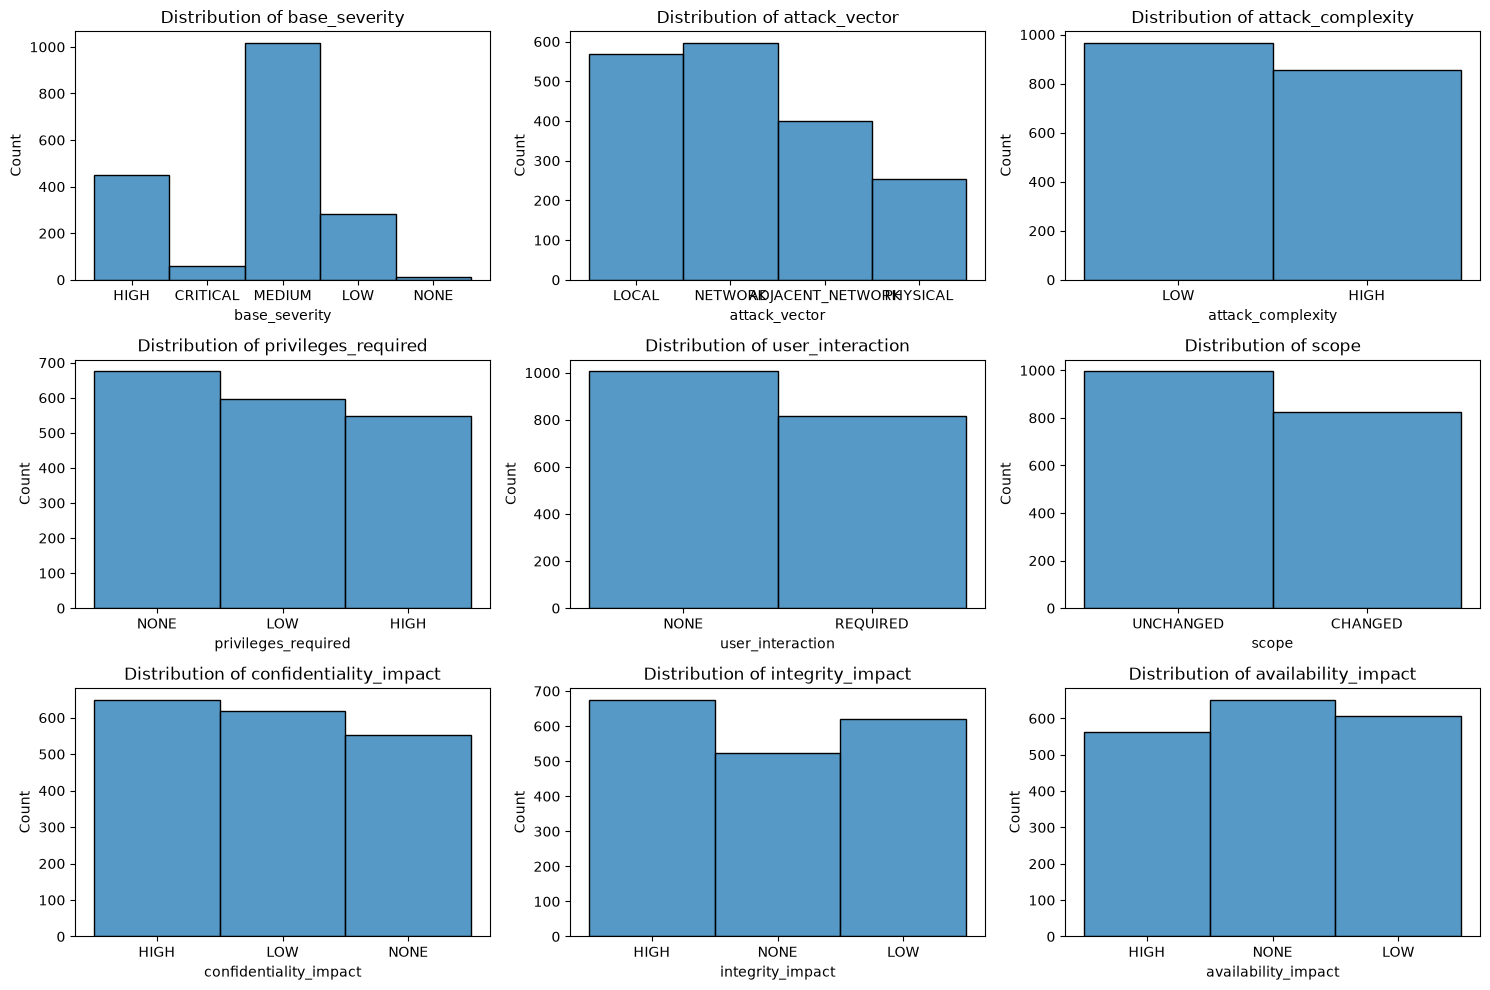

In [211]:
# Visualisasi distribusi data untuk beberapa kolom

plt.figure(figsize=(15, 10))
for i, column in enumerate(df, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[column])
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

In [212]:
# Memisahkan fitur (X) dan target (y)*
X = df.drop(columns=["base_severity"])
x = pd.get_dummies(X)
y = df["base_severity"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y)

# menghitung jumlah data*
print("Jumlah data: ",len(x))
# Menghitung jumlah data pada x_train*
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test*
print("Jumlah data test: ",len(x_test))
x.describe()

Jumlah data:  1820
Jumlah data latih:  1456
Jumlah data test:  364


,attack_vector_ADJACENT_NETWORK,attack_vector_LOCAL,attack_vector_NETWORK,attack_vector_PHYSICAL,attack_complexity_HIGH,attack_complexity_LOW,privileges_required_HIGH,privileges_required_LOW,privileges_required_NONE,user_interaction_NONE,user_interaction_REQUIRED,scope_CHANGED,scope_UNCHANGED,confidentiality_impact_HIGH,confidentiality_impact_LOW,confidentiality_impact_NONE,integrity_impact_HIGH,integrity_impact_LOW,integrity_impact_NONE,availability_impact_HIGH,availability_impact_LOW,availability_impact_NONE
count,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820,1820
unique,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2
top,False,False,False,False,False,True,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False
freq,1420,1251,1224,1565,965,965,1271,1224,1145,1005,1005,995,995,1171,1202,1267,1145,1199,1296,1257,1214,1169


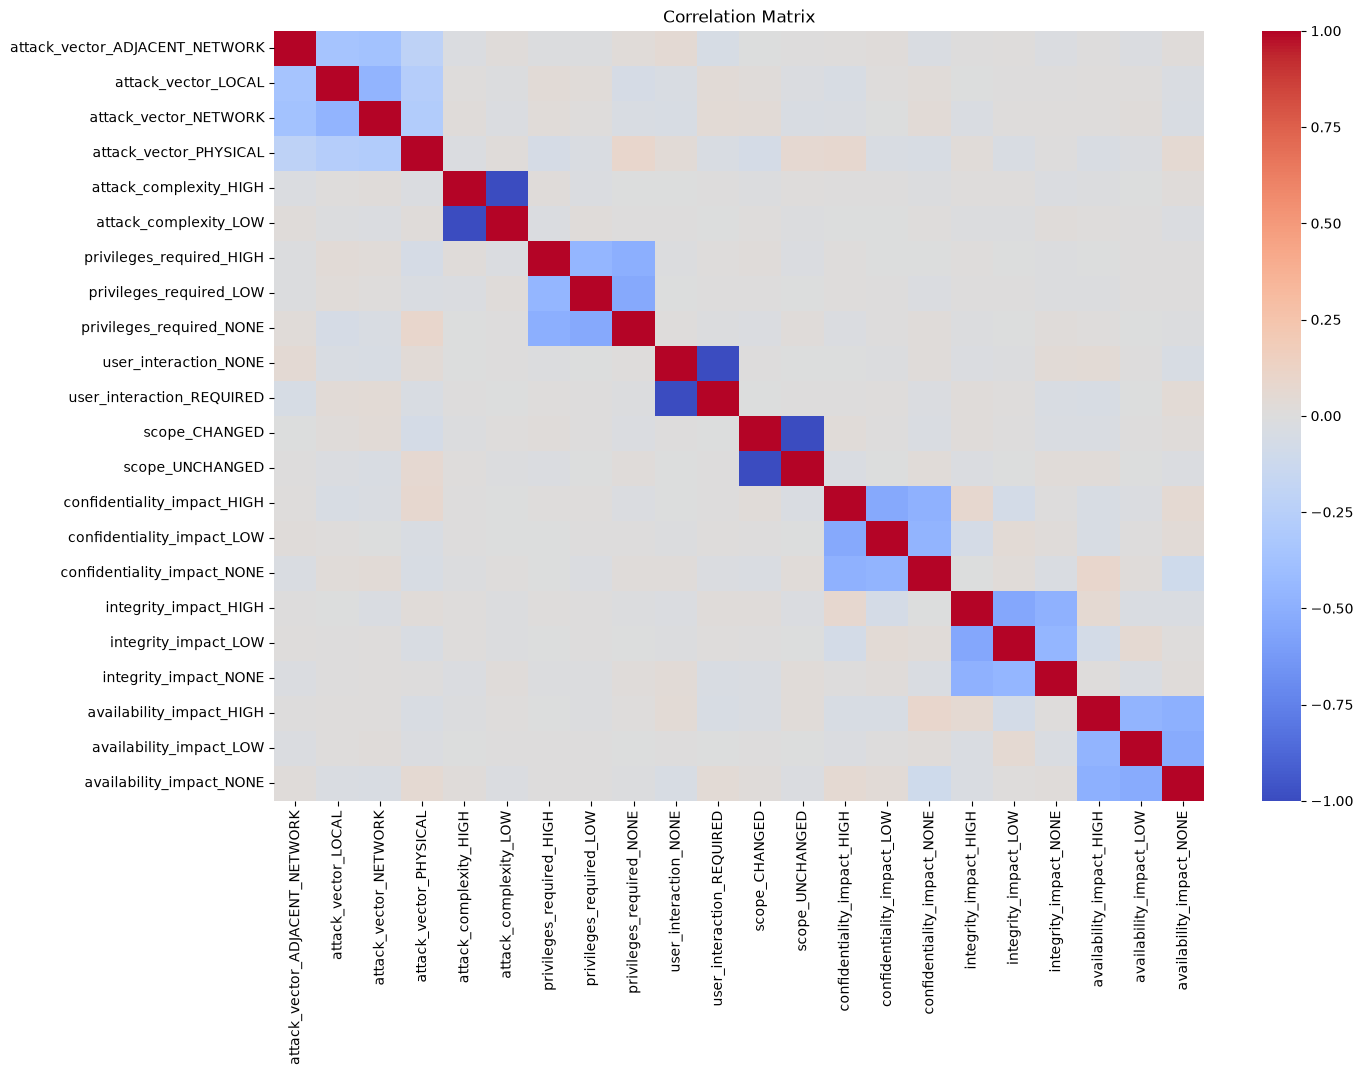

In [213]:
# Visualisasi korelasi antar variabel
plt.figure(figsize=(15, 10))
correlation_matrix = x.corr()

sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

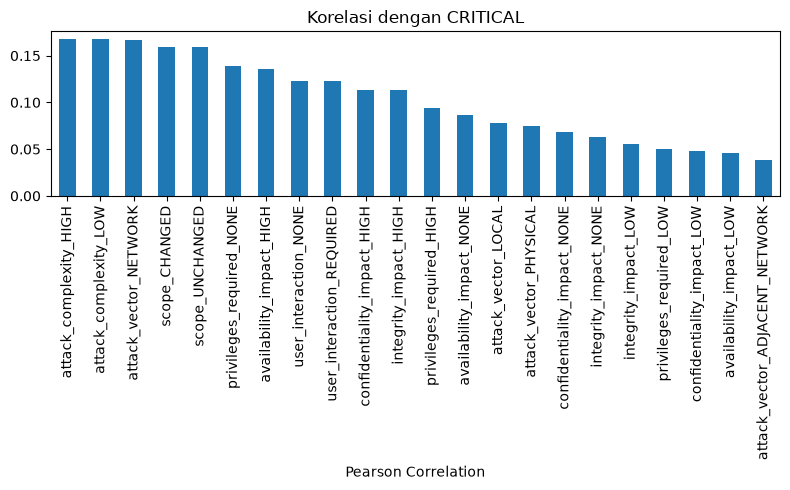

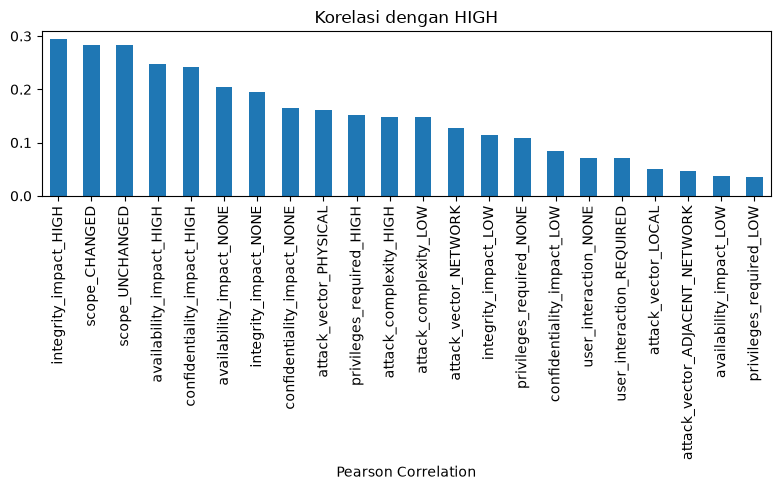

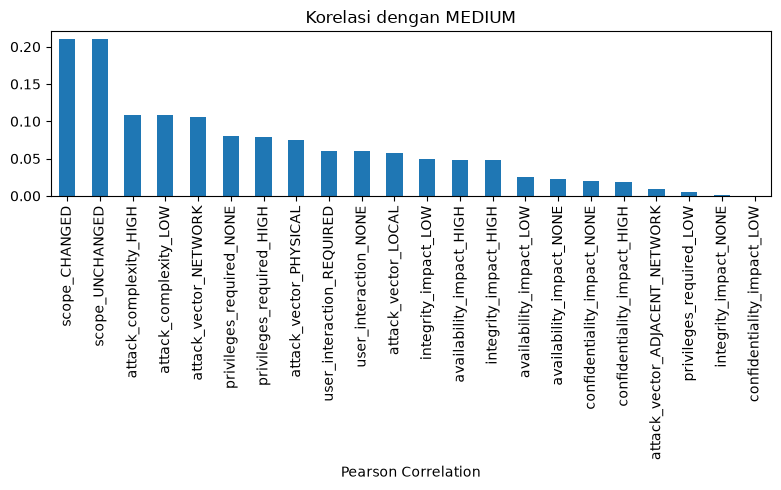

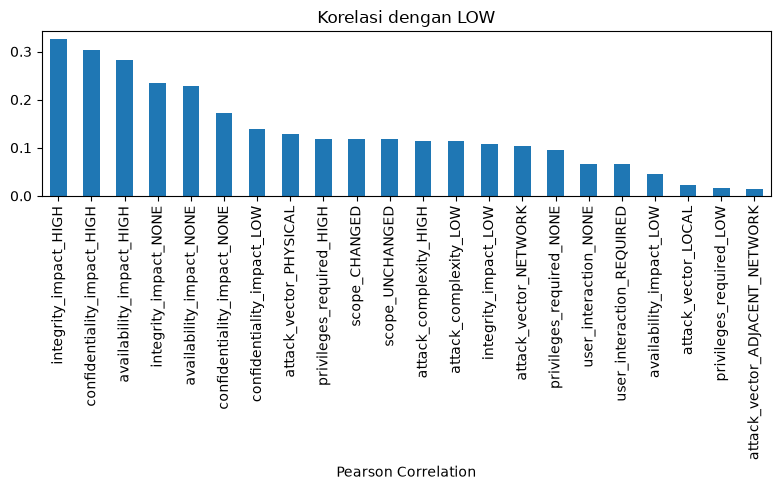

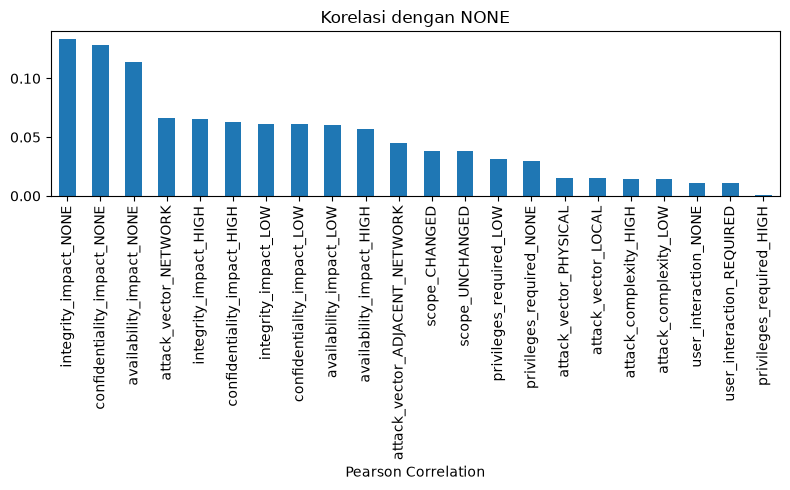

In [214]:
kelas_target = ["CRITICAL", "HIGH", "MEDIUM", "LOW", "NONE"]

for kelas in kelas_target:
    target = y.eq(kelas)

    correlation_matrix = x.corrwith(target).abs().sort_values(ascending=False)

    correlation_matrix.plot(kind="bar", figsize=(8, 5))
    plt.title(f"Korelasi dengan {kelas}")
    plt.xlabel("Pearson Correlation")
    plt.tight_layout()
    plt.show()


In [215]:
# Melatih Model
# Model Random Forest
rfc = RandomForestClassifier(
    n_estimators=100,
    random_state=1,
    n_jobs=-1
).fit(x_train, y_train)

# Model Decision Tree
dct = DecisionTreeClassifier(random_state=1).fit(x_train, y_train)

In [216]:
# Evaluasi pada model Random Forest
rfc_pred = rfc.predict(x_test)

accuracy_rfc = accuracy_score(y_test, rfc_pred)
precision_rfc = precision_score(y_test, rfc_pred, average="macro", zero_division=0)
f1_rfc = f1_score(y_test, rfc_pred, average="macro", zero_division=0)
recall_rfc = recall_score(y_test, rfc_pred, average="macro", zero_division=0)
classification_report_rfc = classification_report(y_test, rfc_pred, digits=4, zero_division=0)

print(f"Hasil RFC:\n{classification_report_rfc}")
# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    "accuracy": [accuracy_rfc],
    "precision":[precision_rfc],
    "recall": [recall_rfc],
    "f1": [f1_rfc]
}

df_results = pd.DataFrame(data, index=["RandomForestClassifier"])
df_results

Hasil RFC:
              precision    recall  f1-score   support

    CRITICAL     1.0000    0.2500    0.4000        12
        HIGH     0.7684    0.8111    0.7892        90
         LOW     0.8148    0.7857    0.8000        56
      MEDIUM     0.8619    0.8916    0.8765       203
        NONE     1.0000    0.6667    0.8000         3

    accuracy                         0.8324       364
   macro avg     0.8890    0.6810    0.7331       364
weighted avg     0.8372    0.8324    0.8268       364



,accuracy,precision,recall,f1
RandomForestClassifier,0.832418,0.889028,0.681024,0.733141


In [217]:
# Evaluasi pada model Decision Tree
dct_pred = dct.predict(x_test)
accuracy_dct = accuracy_score(y_test, dct_pred)
precision_dct = precision_score(y_test, dct_pred, average="macro", zero_division=0)
f1_dct = f1_score(y_test, dct_pred, average="macro", zero_division=0)
recall_dct = recall_score(y_test, dct_pred, average="macro", zero_division=0)
classification_report_dct = classification_report(y_test, dct_pred, digits=4, zero_division=0)

print(f"Hasil RFC:\n{classification_report_dct}")
# Membuat dictionary untuk menyimpan hasil evaluasi
df_results.loc["Decision Tree"] = [accuracy_dct, precision_dct, recall_dct, f1_dct]
df_results

Hasil RFC:
              precision    recall  f1-score   support

    CRITICAL     0.5385    0.5833    0.5600        12
        HIGH     0.6947    0.7333    0.7135        90
         LOW     0.7797    0.8214    0.8000        56
      MEDIUM     0.8564    0.8227    0.8392       203
        NONE     1.0000    0.6667    0.8000         3

    accuracy                         0.7912       364
   macro avg     0.7739    0.7255    0.7425       364
weighted avg     0.7953    0.7912    0.7926       364



,accuracy,precision,recall,f1
RandomForestClassifier,0.832418,0.889028,0.681024,0.733141
Decision Tree,0.791209,0.773854,0.725484,0.742542


In [218]:

y_train_dt = dct.predict(x_train)
y_test_dt = dct.predict(x_test)

print("Decision Tree")
print("Training Accuracy:",
      accuracy_score(y_train, y_train_dt))
print("Testing Accuracy:",
      accuracy_score(y_test, y_test_dt))

print("Training Macro F1:",
      f1_score(y_train, y_train_dt,
               average="macro", zero_division=0))
print("Testing Macro F1:",
      f1_score(y_test, y_test_dt,
               average="macro", zero_division=0))


Decision Tree
Training Accuracy: 1.0
Testing Accuracy: 0.7912087912087912
Training Macro F1: 1.0
Testing Macro F1: 0.7425418986826022


In [219]:

y_train_dt = rfc.predict(x_train)
y_test_dt = rfc.predict(x_test)

print("Decision Tree")
print("Training Accuracy:",
      accuracy_score(y_train, y_train_dt))
print("Testing Accuracy:",
      accuracy_score(y_test, y_test_dt))

print("Training Macro F1:",
      f1_score(y_train, y_train_dt,
               average="macro", zero_division=0))
print("Testing Macro F1:",
      f1_score(y_test, y_test_dt,
               average="macro", zero_division=0))


Decision Tree
Training Accuracy: 1.0
Testing Accuracy: 0.8324175824175825
Training Macro F1: 1.0
Testing Macro F1: 0.7331405012760944


In [220]:
joblib.dump(rfc, "rfc_model.joblib")
joblib.dump(dct, "dct_model.joblib")

['dct_model.joblib']